# FMUCD: explore maintenance work and prepare clustering data

We want to find families of similar maintenance work and test whether those families help predict **work-order duration**. This notebook examines the records, compares two text inputs, and saves datasets for the next stage.

1. Check missing values, duplicate orders, and the duration target.
2. Compare universities, locations, maintenance types, priorities, and building characteristics.
3. Examine description quality, repeated descriptions, and changes over time.
4. Save text, numeric aggregate features, and outcomes as separate tables.

`WODuration` is elapsed **days**, not hands-on labor hours. Families will be learned later; this notebook does not fit embeddings or clustering models. Each section ends with a short summary calculated from the data.

Source: Pampana et al. (2024), [FMUCD, version 1](https://data.mendeley.com/datasets/cb8d2nsjss/1), CC BY 4.0. [Dataset paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC11465139/).

## Field guide

| Group | Fields | Meaning |
| --- | --- | --- |
| University | `UniversityID`, `Country`, `State/Province` | Institution and location. |
| Building | `BuildingID`, `BuildingName`, `Size`, `Type`, `BuiltYear` | Building identity, floor area in square feet, use, and construction year. |
| Building condition | `FCI (facility condition index)`, `CRV (current replacement value)`, `DMC (deferred maintenance cost)` | Repair needs relative to replacement value, replacement cost, and deferred-maintenance cost. FCI is stored as a ratio. |
| Classification | `SystemCode`, `SystemDescription`, `SubsystemCode`, `SubsystemDescription`, `DescriptiveCode`, `ComponentDescription` | Existing system, subsystem, and component categories. A component code is not an individual equipment ID. |
| Work order | `WOID`, `WODescription`, `WOPriority`, `PPM/UPM` | Order identity, work description, local priority code, and planned preventive (PPM) or unplanned (UPM) maintenance. |
| Dates and target | `WOStartDate`, `WOEndDate`, `WODuration` | Recorded dates and elapsed duration in days. |
| Completed work | `LaborHours`, `LaborCost`, `MaterialCost`, `OtherCost`, `TotalCost` | Recorded effort and costs. Exclude these from initial-duration predictors. |
| Weather | Minimum/maximum temperature, pressure, humidity, wind speed/direction, precipitation, snow, and cloud cover | Conditions on the recorded start day. Units are in the CSV headers except wind direction, which is in degrees. |

Use university together with building/order IDs. Treat priority as a category until local scales are understood. Condition assessments and full-day weather may have been recorded too late for an initial prediction, so they are explored but not exported as default predictors. Missing values and zeroes are different.

## 1. Load and check the records

Read identifiers as text to preserve leading zeroes. Keep the CSV unchanged. Remove only fully identical rows from the working data; retain and flag conflicting records sharing the same university/order ID.

In [1]:
from pathlib import Path
import json
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': False})

# Works when launched from this folder or from its parent.
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'data/FMUCD.csv').exists() else Path.cwd() / 'fmucd_analysis'
DATA_PATH = PROJECT_DIR / 'data/FMUCD.csv'
OUTPUT_DIR = PROJECT_DIR / 'data/clustering'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

id_columns = ['UniversityID', 'BuildingID', 'WOID', 'WOPriority',
              'SystemCode', 'SubsystemCode', 'DescriptiveCode']
t0 = time.perf_counter()
df_raw = pd.read_csv(DATA_PATH, dtype={c: 'string' for c in id_columns}, low_memory=False)
exact_duplicate_count = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().copy()
df.insert(0, 'record_id', df.index.astype('int64'))

text_columns = ['WODescription', 'SystemDescription', 'SubsystemDescription', 'ComponentDescription']
for column in text_columns:
    df[column] = df[column].astype('string').str.strip().replace('', pd.NA)
numeric_columns = ['WODuration', 'LaborHours', 'LaborCost', 'MaterialCost', 'OtherCost',
                   'TotalCost', 'Size', 'BuiltYear', 'FCI (facility condition index)',
                   'CRV (current replacement value)', 'DMC (deferred maintenance cost)']
parse_failures = {}
for column in numeric_columns:
    original_values = df[column]
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())
for column in ['WOStartDate', 'WOEndDate']:
    original_values = df[column]
    df[column] = pd.to_datetime(original_values, format='mixed', errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

df['duplicate_order_key'] = df.duplicated(['UniversityID', 'WOID'], keep=False)
df['missing_order_key'] = df[['UniversityID', 'WOID']].isna().any(axis=1)
field_quality = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_rows': df_raw.isna().sum(),
    'missing_pct': df_raw.isna().mean().mul(100).round(2),
    'unique_nonmissing': df_raw.nunique(dropna=True),
}).sort_values('missing_pct', ascending=False)
display(df.head(3))
display(field_quality)
display(pd.Series(parse_failures, name='Values not parsed').to_frame())
display(Markdown(f"**Summary:** Loaded {len(df_raw):,} rows and {df_raw.shape[1]} source fields in {time.perf_counter()-t0:.1f} seconds. "
    f"Removed {exact_duplicate_count:,} fully identical rows. "
    f"{df['duplicate_order_key'].sum():,} remaining rows share a university/order key; "
    "these need review and will be excluded from the default export rather than arbitrarily choosing one."))

,record_id,UniversityID,Country,State/Province,BuildingID,BuildingName,Size,Type,BuiltYear,FCI (facility condition index),...,MaxTemp.(°C),Atmospheric pressure(hPa),Humidity(%),WindSpeed(m/s),WindDegree,Precipitation(mm),Snow(mm),Cloudness(%),duplicate_order_key,missing_order_key
0,0,1,Canada,Nova Scotia,A050,COBURG ROAD 6414,5529.0,Research,1942.0,0.786664,...,0.299583,1023.291667,82.541667,2.379167,170.583333,0.0,0.00,87.583333,False,False
1,1,1,Canada,Nova Scotia,<NA>,NaN,NaN,NaN,NaN,NaN,...,-0.784167,998.125000,75.625000,4.229167,278.541667,0.0,0.11,77.500000,False,False
2,2,1,Canada,Nova Scotia,C201,LSC-BIOL&EARTH,161395.0,Mixed Teaching/Research,1971.0,0.449394,...,-1.926667,1017.250000,84.208333,1.924167,254.833333,0.0,4.42,88.375000,False,False


,dtype,missing_rows,missing_pct,unique_nonmissing
FCI (facility condition index),float64,3304007,88.55,359
Size,float64,3301669,88.48,380
DMC (deferred maintenance cost),str,3301669,88.48,338
CRV (current replacement value),float64,3301669,88.48,378
Type,str,3301669,88.48,23
OtherCost,float64,3087808,82.75,31308
BuiltYear,float64,2844048,76.22,126
MaterialCost,float64,2687497,72.02,117544
BuildingName,str,2294841,61.50,2585
WindDegree,float64,2007402,53.80,4257


,Values not parsed
WODuration,0
LaborHours,0
LaborCost,0
MaterialCost,0
OtherCost,0
TotalCost,0
Size,0
BuiltYear,0
FCI (facility condition index),0
CRV (current replacement value),0


**Summary:** Loaded 3,731,442 rows and 38 source fields in 51.6 seconds. Removed 482,545 fully identical rows. 726,355 remaining rows share a university/order key; these need review and will be excluded from the default export rather than arbitrarily choosing one.

## 2. Is duration a usable target?

Compare recorded duration with the dates. Show the full distribution and a closer view of the first 99%. The closer view changes only the plot; it does not delete long orders. Compare other outcomes for context, without using completed-work costs or hours as predictors.

,missing_pct,zero_pct,negative_rows,median,p90,p99,maximum
WODuration,42.27,4.62,0,14.00,86.00,369.00,32892.00
LaborHours,4.34,10.39,577,1.00,5.00,32.50,34292.25
LaborCost,42.46,6.29,40,56.16,314.60,2115.37,1099741.50
TotalCost,44.17,5.18,154,58.61,415.29,3702.23,1849760.00


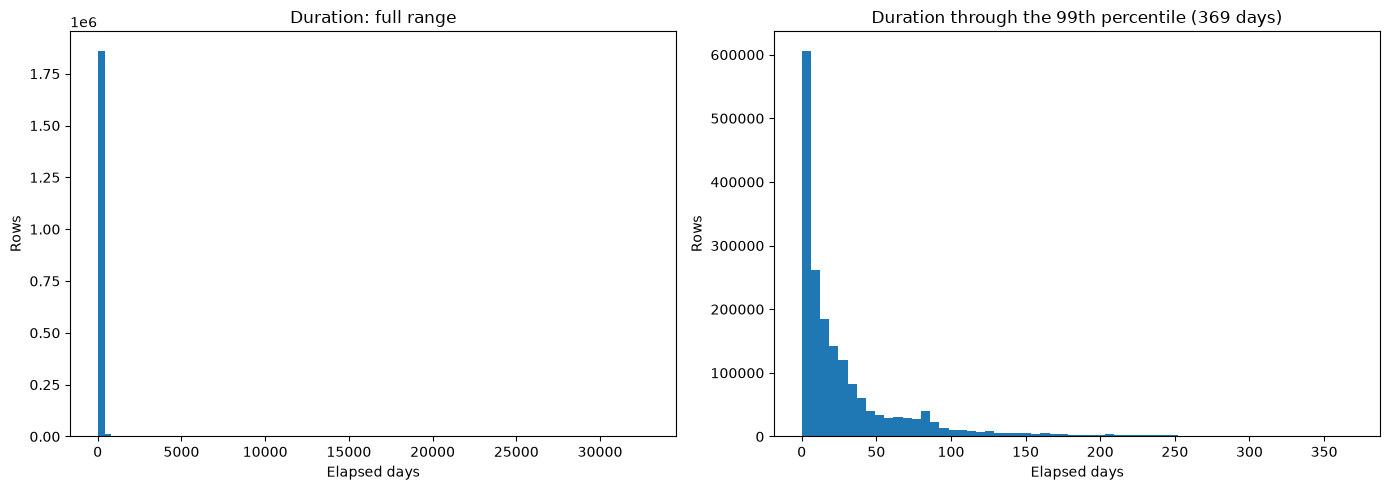

,Rows
Missing/unparseable start date,0
Missing/unparseable end date,1413122
End before start,12202
Missing duration but valid date pair (possible recovery),10054
Valid recorded target but inconsistent/missing dates,61989
Duration over one year,19345


,UniversityID,WOID,WODescription,WOStartDate,WOEndDate,WODuration
1474971,8,WO411925,REPLACE BURNER,2016-01-14 00:00:00,2016-02-03 00:00:00,32892.0
1746177,10,30000001,DO NOT USE - ZONE 1 TROUBLE CALLS,2003-01-31 17:04:05,2020-11-24 09:37:01,6506.0
1884096,10,31303090,GRE: SERVICES REPAIRS TO INFRASTRUCTURE AND COMMON AREAS,2003-01-30 16:49:26,2020-09-23 13:07:11,6445.0
2579522,10,36000496,AND - PROVIDE MAINTENANCE OF FIRE ALARM SYSTEM,2003-02-11 11:00:24,2020-01-21 11:06:06,6188.0
2704361,10,36046048,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-07-28 07:51:07,2020-04-23 10:22:53,6114.0
2442447,10,36056807,MTHLY-BUILDING AIR COMP. MAINTENANCE INSTRUCTIONS,2003-09-01 11:16:09,2018-04-11 16:44:41,5336.0
2016992,10,36063358,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-09-22 15:20:53,2018-04-11 16:44:41,5315.0
2133116,10,36063617,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-09-22 15:44:32,2018-04-11 16:44:41,5315.0


**Summary:** 42.3% of working rows have no usable recorded duration. The median nonnegative duration is 14.0 days; 90% are at or below 86.0 days. 61,989 target-bearing rows fail the one-day date-agreement check. 1,681 of 374,178 complete cost records differ from the sum of their components by more than $0.05. Use WODuration as elapsed completion time. Keep long durations for now and audit flagged rows before deciding on a narrower target population.

In [2]:
elapsed_days = (df['WOEndDate'] - df['WOStartDate']).dt.total_seconds() / 86400
df['date_elapsed_days'] = elapsed_days
df['duration_date_gap'] = df['WODuration'] - elapsed_days
df['valid_target'] = df['WODuration'].notna() & np.isfinite(df['WODuration']) & df['WODuration'].ge(0)
df['valid_dates'] = df['WOStartDate'].notna() & df['WOEndDate'].notna() & elapsed_days.ge(0)
df['duration_date_consistent'] = df['valid_dates'] & df['duration_date_gap'].abs().le(1)

target_columns = ['WODuration', 'LaborHours', 'LaborCost', 'TotalCost']
target_quality = pd.DataFrame({
    'missing_pct': df[target_columns].isna().mean().mul(100),
    'zero_pct': df[target_columns].eq(0).mean().mul(100),
    'negative_rows': df[target_columns].lt(0).sum(),
    'median': df[target_columns].median(),
    'p90': df[target_columns].quantile(.90),
    'p99': df[target_columns].quantile(.99),
    'maximum': df[target_columns].max(),
})
display(target_quality.round(2))
duration = df.loc[df['valid_target'], 'WODuration']
p99 = duration.quantile(.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(duration, bins=80)
axes[0].set(title='Duration: full range', xlabel='Elapsed days', ylabel='Rows')
axes[1].hist(duration[duration.le(p99)], bins=60)
axes[1].set(title=f'Duration through the 99th percentile ({p99:,.0f} days)', xlabel='Elapsed days', ylabel='Rows')
plt.tight_layout(); plt.show()

date_audit = pd.Series({
    'Missing/unparseable start date': df['WOStartDate'].isna().sum(),
    'Missing/unparseable end date': df['WOEndDate'].isna().sum(),
    'End before start': elapsed_days.lt(0).sum(),
    'Missing duration but valid date pair (possible recovery)': (df['WODuration'].isna() & df['valid_dates']).sum(),
    'Valid recorded target but inconsistent/missing dates': (df['valid_target'] & ~df['duration_date_consistent']).sum(),
    'Duration over one year': duration.gt(365).sum(),
}, name='Rows')
display(date_audit.to_frame())
display(df.nlargest(8, 'WODuration')[['UniversityID', 'WOID', 'WODescription', 'WOStartDate', 'WOEndDate', 'WODuration']])
cost_sum = df[['LaborCost', 'MaterialCost', 'OtherCost']].sum(axis=1, min_count=3)
cost_comparable = cost_sum.notna() & df['TotalCost'].notna()
cost_mismatch = cost_comparable & (cost_sum - df['TotalCost']).abs().gt(.05)
display(Markdown(f"**Summary:** {df['WODuration'].isna().mean():.1%} of working rows have no usable recorded duration. "
    f"The median nonnegative duration is {duration.median():,.1f} days; "
    f"90% are at or below {duration.quantile(.9):,.1f} days. "
    f"{date_audit['Valid recorded target but inconsistent/missing dates']:,} target-bearing rows fail the one-day date-agreement check. "
    f"{cost_mismatch.sum():,} of {cost_comparable.sum():,} complete cost records differ from the sum of their components by more than $0.05. "
    "Use WODuration as elapsed completion time. Keep long durations for now and audit flagged rows before deciding on a narrower target population."))

## 3. Universities, states, maintenance types, and priorities

Compare counts and duration percentiles. State differences may reflect university practices. Priority codes are compared within universities, not treated as a common numerical scale.

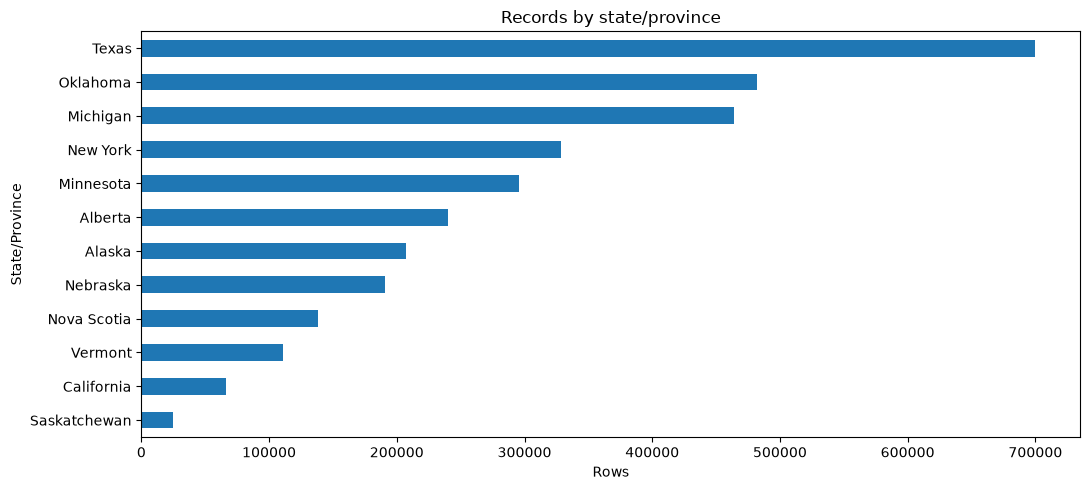

,rows,median_days,p90_days,zero_pct
State/Province,,,,
Texas,699750,10.0,50.0,4.24
Minnesota,289975,27.0,87.0,6.72
Alberta,240168,22.0,116.0,2.59
Nebraska,187630,14.0,57.0,0.00
Nova Scotia,134421,30.0,160.0,0.00
New York,133568,36.0,216.0,0.00
Vermont,99035,3.0,94.0,27.48
California,65936,0.0,0.0,94.72
Saskatchewan,25024,7.0,71.0,19.70


,rows,median_days,p90_days,zero_pct
UniversityID,,,,
10,699750,10.0,50.0,4.24
6,289975,27.0,87.0,6.72
4,240168,22.0,116.0,2.59
9,187630,14.0,57.0,0.00
1,134421,30.0,160.0,0.00
12,133568,36.0,216.0,0.00
8,99035,3.0,94.0,27.48
2,65936,0.0,0.0,94.72
7,25024,7.0,71.0,19.70


,,rows,median_days,p90_days,zero_pct
UniversityID,PPM/UPM,,,,
10,PPM,585720,12.0,49.0,3.27
6,PPM,151734,57.0,87.0,0.30
9,PPM,148704,15.0,61.0,0.00
4,UPM,142378,13.0,140.0,4.32
6,UPM,136332,7.0,71.0,13.70
10,UPM,112375,4.0,54.0,9.13
12,UPM,107671,33.0,195.0,0.00
4,PPM,97790,30.0,96.0,0.07
8,UPM,89818,3.0,82.0,28.42


rows  median_days  p90_days  zero_pct
UniversityID WOPriority                                         
10           1.0         346934         11.0      40.0      3.78
             3.0         189180          9.0      54.0      3.80
             2.0         116930          9.0      53.0      7.19
4            3            94609         15.0     161.0      3.64
             5            90015         30.0      96.0      0.10
9            4-ROUTINE    87077         10.0      54.0      0.00
6            42           69644         50.0      89.0      0.33
             5            61942          4.0      45.0     15.84
9            5-PM         61696         24.0      69.0      0.00
12           30.0         60744         49.0     277.0      0.00
1            3            50500         41.0     238.0      0.00
6            10           49453         10.0      76.0      9.51
             41           46392         72.0      87.0      0.24
8            3.0          42344          7.0     112.0     12.96
2            4-ROUTINE    38804          0.0       0.0     94.53
12           40.0         37627         33.0     181.0      0.00
10           4.0          36202         17.0      84.0      1.64
6            43           34852         44.0      91.0      0.32
1            2            32502         20.0     110.0      0.00
9            2-URGENT     31746          8.0      37.0      0.00
8            2.0          31068          2.0      85.0     27.94
1            1            26702         21.0     119.0      0.00
4            2            22936         19.0     148.0      2.75
             1            22381         14.0      69.0      4.57
2            2-URGENT     19784          0.0       0.0     96.45
12           50.0         18867         28.0     152.0      0.00
8            1.0          18782          0.0       5.0     66.73
12           45.0         16209         21.0     127.0      0.00
1            7            11272         24.0     139.0      0.00
10           5.0          10443         17.0     201.0      3.50

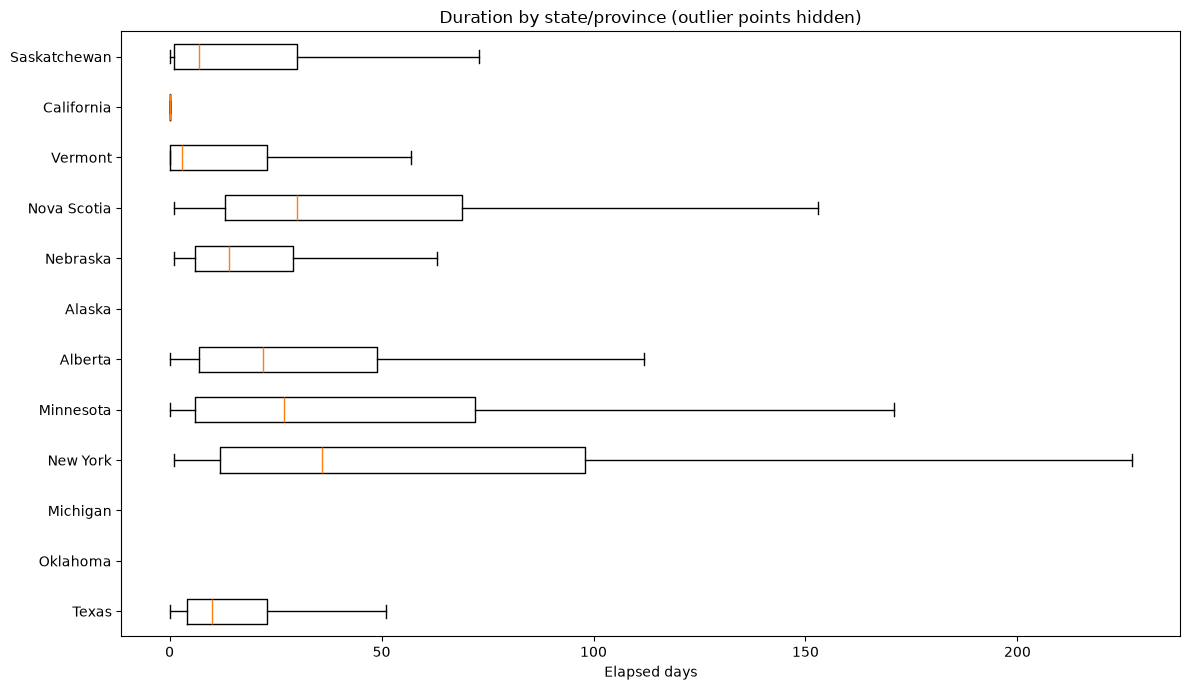

**Summary:** 12 universities contribute data. The largest state/province supplies 21.5% of rows. University median durations range from 0.0 to 36.0 days. Retain university and maintenance type as baseline context. Review the priority table before assigning ordered priority values.

In [3]:
def duration_summary(group_columns):
    return (df.loc[df['valid_target']].groupby(group_columns, dropna=False, observed=True)
            .agg(rows=('record_id', 'size'), median_days=('WODuration', 'median'),
                 p90_days=('WODuration', lambda x: x.quantile(.9)),
                 zero_pct=('WODuration', lambda x: x.eq(0).mean()*100))
            .sort_values('rows', ascending=False))

state_counts = df['State/Province'].fillna('Unknown').value_counts()
state_counts.sort_values().plot.barh(title='Records by state/province', xlabel='Rows')
plt.tight_layout(); plt.show()
display(duration_summary(['State/Province']).round(2))
university_summary = duration_summary(['UniversityID'])
display(university_summary.round(2))
display(duration_summary(['UniversityID', 'PPM/UPM']).round(2))
priority_summary = duration_summary(['UniversityID', 'WOPriority'])
display(priority_summary.head(30).round(2))

groups = [df.loc[df['valid_target'] & df['State/Province'].eq(s), 'WODuration'].to_numpy()
          for s in state_counts.index if s != 'Unknown']
labels = [s for s in state_counts.index if s != 'Unknown']
fig, ax = plt.subplots(figsize=(12, 7))
ax.boxplot(groups, orientation='horizontal', showfliers=False, tick_labels=labels)
ax.set(title='Duration by state/province (outlier points hidden)', xlabel='Elapsed days')
plt.tight_layout(); plt.show()
display(Markdown(f"**Summary:** {df['UniversityID'].nunique():,} universities contribute data. "
    f"The largest state/province supplies {state_counts.iloc[0]/len(df):.1%} of rows. "
    f"University median durations range from {university_summary['median_days'].min():,.1f} to "
    f"{university_summary['median_days'].max():,.1f} days. "
    "Retain university and maintenance type as baseline context. Review the priority table before assigning ordered priority values."))

## 4. Building characteristics and existing categories

Check coverage before choosing predictors. Building area, use, and age are candidates. Condition assessments and building values are kept for exploration because their assessment dates are unknown. Building distributions below use one unambiguous metadata combination per university/building, not one point per work order.

,Size,Type,BuiltYear,FCI (facility condition index),CRV (current replacement value),DMC (deferred maintenance cost)
UniversityID,,,,,,
1,4.4,4.4,4.4,4.4,4.4,4.4
10,100.0,100.0,100.0,100.0,100.0,100.0
11,100.0,100.0,5.6,100.0,100.0,100.0
12,100.0,100.0,100.0,100.0,100.0,100.0
2,100.0,100.0,100.0,100.0,100.0,100.0
3,100.0,100.0,100.0,100.0,100.0,100.0
4,100.0,100.0,100.0,100.0,100.0,100.0
5,100.0,100.0,100.0,100.0,100.0,100.0
6,0.9,0.9,0.9,1.7,0.9,1.0


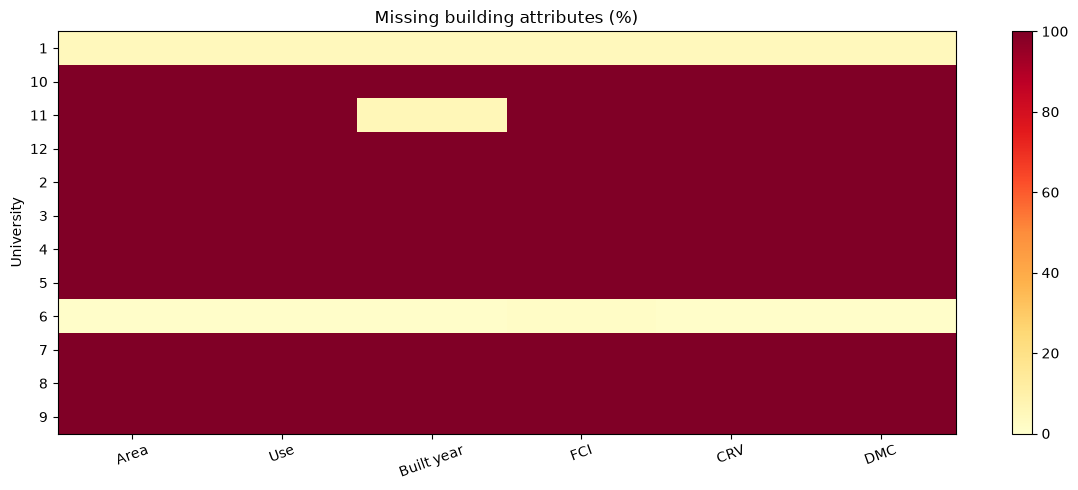

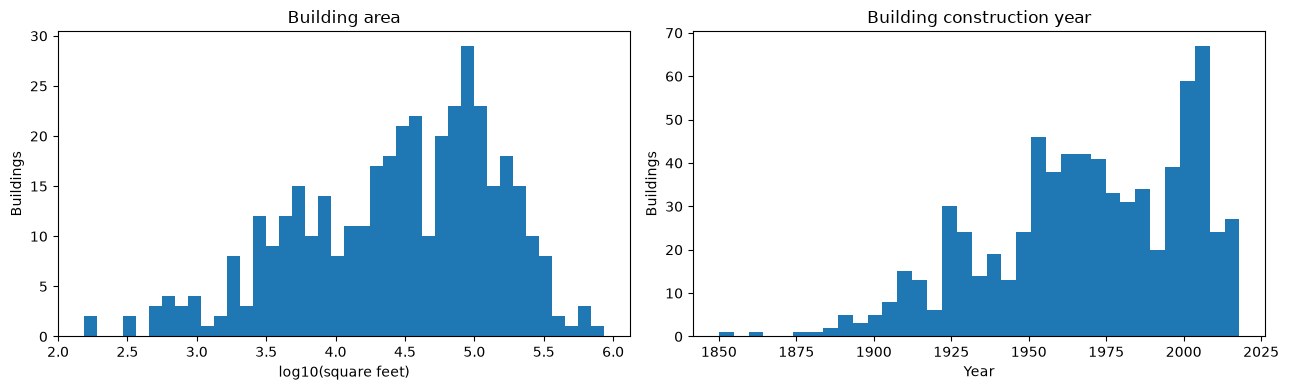

,unique,missing_pct
SystemCode,23.0,1.44
SubsystemCode,88.0,1.44
DescriptiveCode,470.0,1.44
Type,23.0,86.90


,rows,median_days,p90_days,zero_pct
SystemDescription,,,,
Electrical,557502,10.0,57.0,5.85
HVAC,489064,19.0,94.0,7.77
Plumbing,302607,13.0,85.0,9.79
Fire Protection,123976,21.0,94.0,9.45
Equipment,100709,21.0,91.0,11.42
Interior Construction,90301,7.0,80.0,12.41
Interior Finishes,45445,19.0,132.0,7.39
Exterior Enclosure,38340,13.0,91.0,7.16
General,32302,30.0,92.0,4.30


,Count
Subsystem codes with multiple descriptions,65
Component codes with multiple descriptions,1
Building keys with varying metadata,148
Rows with construction after work-order start,598
Rows with nonpositive building size,0


,rows,median_days
Size band,,
"(152.999, 46114.0]",85889,34.0
"(46114.0, 94988.0]",80886,29.0
"(94988.0, 155439.0]",83406,26.0
"(155439.0, 259989.0]",86568,27.0
"(259989.0, 862133.0]",79216,22.0


,rows,median_days
BuildingAge band,,
"(-0.001, 25.0]",84001,29.0
"(25.0, 46.0]",87127,26.0
"(46.0, 57.0]",80772,29.0
"(57.0, 71.0]",81050,26.0
"(71.0, 169.0]",82421,29.0


**Summary:** There are 4,039 university/building keys and 148 have varying building metadata. 86.9% of rows lack building area and 86.9% lack building use. The size/age tables show associations across orders, not causal effects; university differences may explain them. Keep missing values explicit. Existing system/component categories provide a useful baseline for learned families.

In [4]:
building_fields = ['Size', 'Type', 'BuiltYear', 'FCI (facility condition index)',
                   'CRV (current replacement value)', 'DMC (deferred maintenance cost)']
missing_by_university = (df.groupby('UniversityID')[building_fields].agg(lambda x: x.isna().mean()*100))
display(missing_by_university.round(1))
fig, ax = plt.subplots(figsize=(12, 5))
heat = ax.imshow(missing_by_university.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='YlOrRd')
ax.set_xticks(range(len(building_fields)), ['Area', 'Use', 'Built year', 'FCI', 'CRV', 'DMC'], rotation=20)
ax.set_yticks(range(len(missing_by_university)), missing_by_university.index)
ax.set(title='Missing building attributes (%)', ylabel='University')
fig.colorbar(heat, ax=ax); plt.tight_layout(); plt.show()

df['BuildingAge'] = df['WOStartDate'].dt.year - df['BuiltYear']
negative_age_count = int(df['BuildingAge'].lt(0).sum())
df.loc[df['BuildingAge'].lt(0), 'BuildingAge'] = np.nan
nonpositive_size_count = int(df['Size'].le(0).sum())
building_meta = df.dropna(subset=['UniversityID', 'BuildingID'])[['UniversityID', 'BuildingID'] + building_fields].drop_duplicates()
building_variants = building_meta.groupby(['UniversityID', 'BuildingID']).size()
unambiguous_keys = building_variants[building_variants.eq(1)].index
building_sample = building_meta.set_index(['UniversityID', 'BuildingID']).loc[unambiguous_keys]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(building_sample.loc[building_sample['Size'].gt(0), 'Size']), bins=40)
axes[0].set(title='Building area', xlabel='log10(square feet)', ylabel='Buildings')
axes[1].hist(building_sample['BuiltYear'].dropna(), bins=35)
axes[1].set(title='Building construction year', xlabel='Year', ylabel='Buildings')
plt.tight_layout(); plt.show()

classification_summary = pd.DataFrame({
    c: {'unique': df[c].nunique(), 'missing_pct': df[c].isna().mean()*100}
    for c in ['SystemCode', 'SubsystemCode', 'DescriptiveCode', 'Type']
}).T
display(classification_summary.round(2))
display(duration_summary(['SystemDescription']).head(20).round(2))
mapping_audit = pd.Series({
    'Subsystem codes with multiple descriptions': (df.groupby('SubsystemCode')['SubsystemDescription'].nunique().gt(1)).sum(),
    'Component codes with multiple descriptions': (df.groupby('DescriptiveCode')['ComponentDescription'].nunique().gt(1)).sum(),
    'Building keys with varying metadata': building_variants.gt(1).sum(),
    'Rows with construction after work-order start': negative_age_count,
    'Rows with nonpositive building size': nonpositive_size_count,
}, name='Count')
display(mapping_audit.to_frame())
for predictor in ['Size', 'BuildingAge']:
    usable = df.loc[df['valid_target'] & df[predictor].notna(), [predictor, 'WODuration']].copy()
    if predictor == 'Size':
        usable = usable.loc[usable[predictor].gt(0)]
    usable['band'] = pd.qcut(usable[predictor], q=5, duplicates='drop')
    display(usable.groupby('band', observed=True).agg(rows=('WODuration', 'size'),
        median_days=('WODuration', 'median')).rename_axis(f'{predictor} band'))
del usable
display(Markdown(f"**Summary:** There are {len(building_variants):,} university/building keys and "
    f"{int(building_variants.gt(1).sum()):,} have varying building metadata. "
    f"{df['Size'].isna().mean():.1%} of rows lack building area and {df['Type'].isna().mean():.1%} lack building use. "
    "The size/age tables show associations across orders, not causal effects; university differences may explain them. "
    "Keep missing values explicit. Existing system/component categories provide a useful baseline for learned families."))

## 5. Text inputs and repeated descriptions

Build two embedding inputs: the work description alone, and that description with its classification context. Normalize only case and whitespace for grouping. Preserve numbers, punctuation, and maintenance intervals. No embeddings are fitted here.

Repeated descriptions are also examined for duration consistency. This is exploratory: these full-data outcome summaries will not be included in clustering feature exports.

,missing_or_blank_rows,median_characters,p90_characters
Description only,914,50.0,138.0
Description with context,4,144.0,228.0


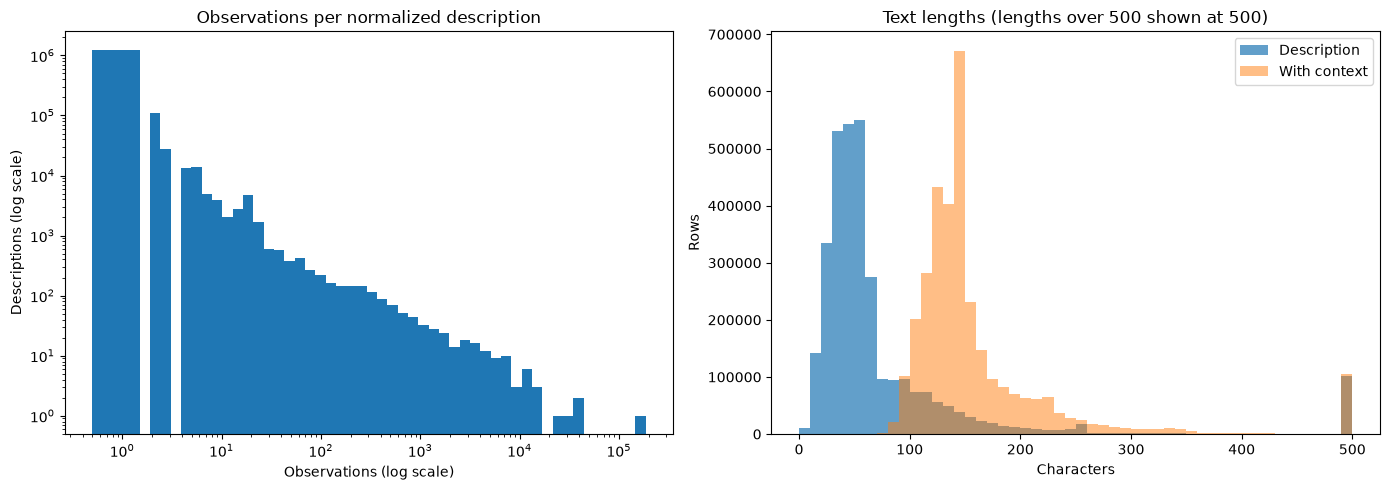

,rows,universities,median_days,components,q25,q75,iqr_days
description_key,,,,,,,
monthly emergency&exit light inspection (1x month),185311,1,8.0,1,4.0,19.0,15.0
monthly 000 emergency light inspection (1x month),40710,1,16.0,1,8.0,31.0,23.0
general material condition: work performed on equipment or a property,31234,1,0.0,113,0.0,0.0,0.0
supply / return / interlocked exhaust fan inspection,22439,1,79.0,11,65.0,87.0,22.0
quarterly fan pm (all stand alone fans),16304,1,15.0,1,7.0,29.0,22.0
safety shower and eyewash fountain inspection annually.,11554,1,83.0,3,72.0,85.0,13.0
strobe fume fan inspection,10787,1,76.0,1,56.0,85.0,29.0
098: light emrg (1x month),8740,1,14.0,1,8.0,22.0,14.0
annual safety eyewash & shower pm,8580,1,7.0,1,5.0,17.0,12.0


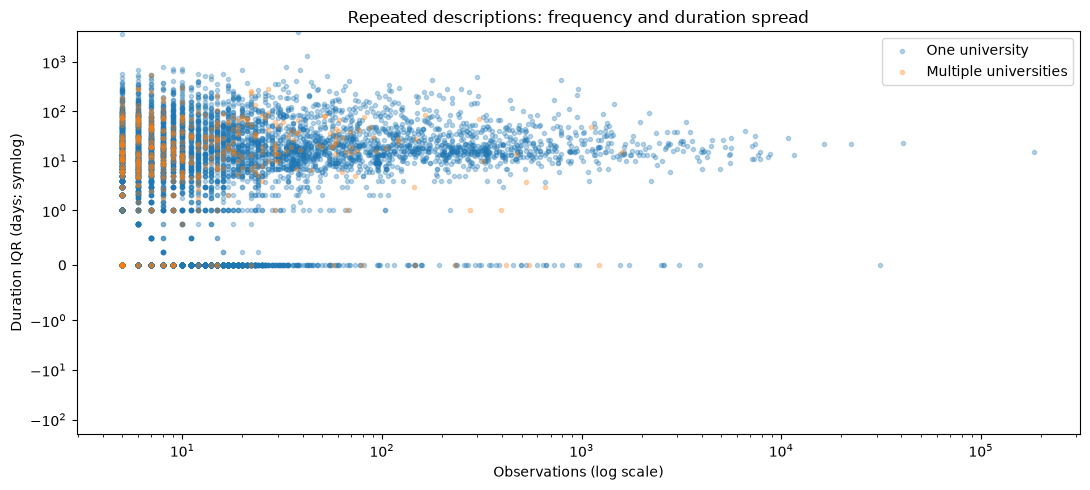

,text_wo,text_context
2510682,MONTHLY EMERGENCY&EXIT LIGHT INSPECTION (1X MONTH),Work: MONTHLY EMERGENCY&EXIT LIGHT INSPECTION (1X MONTH)\nSystem: Electrical\nSubsyste...
2529739,ANNUAL 092 I&C INSPECTION-PM ROUTE,Work: ANNUAL 092 I&C INSPECTION-PM ROUTE\nSystem: HVAC\nSubsystem: Distribution System...
1294606,159//215/SINK TRAP IS LEAKING - REPAIR,Work: 159//215/SINK TRAP IS LEAKING - REPAIR\nSystem: Plumbing\nSubsystem: Plumbing Fi...
663859,BACKFLOW PREVENTER-ANNUAL TESTING,Work: BACKFLOW PREVENTER-ANNUAL TESTING\nSystem: Plumbing\nSubsystem: Domestic Water D...
3433729,MM 8111 Jammed door,Work: MM 8111 Jammed door\nSystem: Interior Construction\nSubsystem: Interior Doors\n...


**Summary:** There are 1,441,491 exact nonmissing descriptions and 1,436,735 after case/whitespace normalization. 86.8% of normalized descriptions appear once. Among 13,126 descriptions with at least five valid durations, the median within-description IQR is 0.0 days. Repeated wording does not automatically imply consistent duration; compare description-only embeddings with embeddings that include classification context.

In [5]:
df['text_wo'] = df['WODescription'].fillna('')
df['description_key'] = df['text_wo'].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()
df['has_description'] = df['description_key'].ne('')
df['text_context'] = ''
for column, label in [('WODescription', 'Work'), ('SystemDescription', 'System'),
                      ('SubsystemDescription', 'Subsystem'), ('ComponentDescription', 'Component')]:
    values = df[column].fillna('')
    addition = (label + ': ' + values).where(values.ne(''), '')
    df['text_context'] = df['text_context'] + np.where(df['text_context'].ne('') & addition.ne(''), '\n', '') + addition

description_counts = df.loc[df['description_key'].ne(''), 'description_key'].value_counts()
exact_description_count = df['WODescription'].nunique()
text_quality = pd.DataFrame({
    'missing_or_blank_rows': [df['text_wo'].str.strip().eq('').sum(), df['text_context'].str.strip().eq('').sum()],
    'median_characters': [df['text_wo'].str.len().median(), df['text_context'].str.len().median()],
    'p90_characters': [df['text_wo'].str.len().quantile(.9), df['text_context'].str.len().quantile(.9)],
}, index=['Description only', 'Description with context'])
display(text_quality)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
max_count = max(2, int(description_counts.max()))
bins = np.unique(np.r_[.5, np.geomspace(1.5, max_count+.5, 50)])
axes[0].hist(description_counts, bins=bins)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set(title='Observations per normalized description', xlabel='Observations (log scale)', ylabel='Descriptions (log scale)')
axes[1].hist(df['text_wo'].str.len().clip(upper=500), bins=50, alpha=.7, label='Description')
axes[1].hist(df['text_context'].str.len().clip(upper=500), bins=50, alpha=.5, label='With context')
axes[1].set(title='Text lengths (lengths over 500 shown at 500)', xlabel='Characters', ylabel='Rows'); axes[1].legend()
plt.tight_layout(); plt.show()

description_groups = df.loc[df['valid_target'] & df['description_key'].ne(''),
    ['description_key', 'record_id', 'UniversityID', 'WODuration', 'DescriptiveCode']].groupby('description_key')
description_summary = (description_groups.agg(
        rows=('record_id', 'size'), universities=('UniversityID', 'nunique'),
        median_days=('WODuration', 'median'), components=('DescriptiveCode', 'nunique')))
description_quantiles = description_groups['WODuration'].quantile([.25, .75]).unstack()
description_summary['q25'] = description_quantiles[.25]
description_summary['q75'] = description_quantiles[.75]
del description_groups, description_quantiles
description_summary['iqr_days'] = description_summary['q75'] - description_summary['q25']
display(description_summary.nlargest(12, 'rows').round(2))
repeated = description_summary.loc[description_summary['rows'].ge(5)]
scatter_sample = repeated.sample(min(20000, len(repeated)), random_state=42)
fig, ax = plt.subplots()
for shared, label in [(False, 'One university'), (True, 'Multiple universities')]:
    part = scatter_sample.loc[scatter_sample['universities'].gt(1).eq(shared)]
    ax.scatter(part['rows'], part['iqr_days'], s=9, alpha=.3, label=label)
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1)
ax.set(title='Repeated descriptions: frequency and duration spread', xlabel='Observations (log scale)', ylabel='Duration IQR (days; symlog)')
ax.legend(); plt.tight_layout(); plt.show()
display(df[['text_wo', 'text_context']].sample(5, random_state=42))
display(Markdown(f"**Summary:** There are {exact_description_count:,} exact nonmissing descriptions and "
    f"{len(description_counts):,} after case/whitespace normalization. "
    f"{description_counts.eq(1).mean():.1%} of normalized descriptions appear once. "
    f"Among {len(repeated):,} descriptions with at least five valid durations, the median within-description IQR is "
    f"{repeated['iqr_days'].median():,.1f} days. Repeated wording does not automatically imply consistent duration; "
    "compare description-only embeddings with embeddings that include classification context."))

## 6. Time patterns and a chronological split

Check changes in monthly workload and duration. Orders closed together can reflect administrative cleanup. Use earlier dates for training and later dates for validation/test. An order's completed duration can be used for training only if its end date precedes the training cutoff.

The split dates use the 70th and 85th percentiles of eligible start dates, rounded to days. This is a starting evaluation design, not a final tuning choice. Repeated task types may cross the split to test future orders of known work. A separate task-held-out test will be needed to claim performance on unseen work.

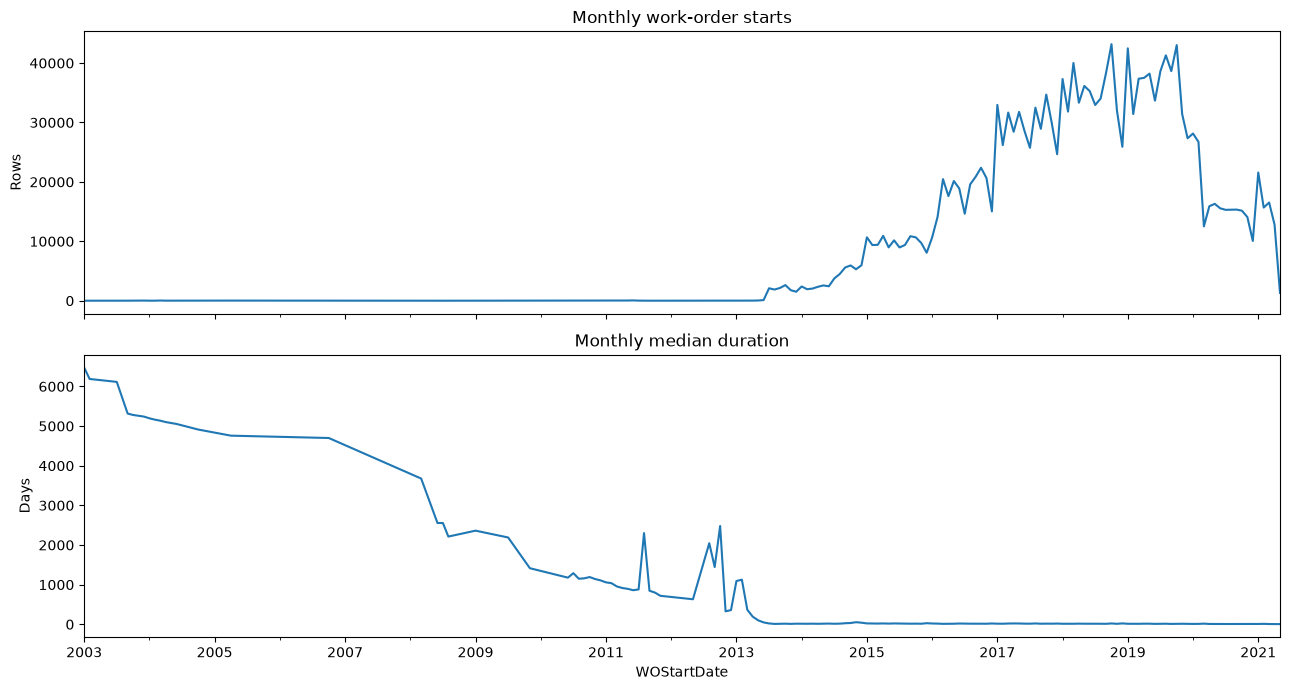

orders_closed
UniversityID close_day                
10           2018-09-07           2967
             2020-04-08           2512
             2019-04-19           2243
             2017-06-13           1663
             2019-06-13           1651
             2017-09-06           1591
             2017-06-20           1565
             2019-01-28           1467
             2017-10-13           1461
             2020-03-18           1455

,Rows (first applicable reason)
exclusion_reason,
Included,1510811
Missing/invalid duration,1373390
Repeated university/order ID,276322
Outcome unavailable at split cutoff,57703
Missing/inconsistent dates,29358
Missing university/order ID,816
Missing work description,497


,rows,start_min,start_max,median_days
split,,,,
excluded,1738086,2002-09-06 12:09:12,2021-05-28 00:00:00,24.0
test,235888,2019-11-20 00:00:00,2021-05-23 19:26:36,7.0
train,1065435,2003-09-01 11:16:09,2019-03-24 00:00:00,16.0
validation,209488,2019-03-25 00:00:00,2019-11-19 09:17:43,10.0


split,excluded,test,train,validation
UniversityID,,,,
1,16379,1538,107416,12842
10,18410,196811,398534,86208
11,482141,0,0,0
12,309373,12393,178,6379
2,63959,1975,2,0
3,207488,0,0,0
4,4900,2641,202090,30537
5,464250,0,0,0
6,69850,11335,168575,46304


**Summary:** Training outcomes must be known before **2019-03-25**. Validation starts on that date; test starts **2019-11-20**. 57,703 otherwise eligible rows are omitted because their outcomes were not known at the relevant cutoff. This prevents using future completions as historical information. It also favors shorter completed orders near boundaries; the source may omit unfinished orders entirely, so evaluate closure lag and censoring before making deployment claims.

In [6]:
monthly = (df.loc[df['valid_target'] & df['WOStartDate'].notna()]
    .groupby(df['WOStartDate'].dt.to_period('M'))
    .agg(rows=('record_id', 'size'), median_days=('WODuration', 'median')))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
monthly['rows'].plot(ax=axes[0], title='Monthly work-order starts', ylabel='Rows')
monthly['median_days'].plot(ax=axes[1], title='Monthly median duration', ylabel='Days')
plt.tight_layout(); plt.show()
close_days = df['WOEndDate'].dt.floor('D')
closure_batches = (df.assign(close_day=close_days).dropna(subset=['close_day'])
    .groupby(['UniversityID', 'close_day']).size().nlargest(10).rename('orders_closed'))
display(closure_batches.to_frame())

df['eligible'] = (df['valid_target'] & df['duration_date_consistent']
    & ~df['duplicate_order_key'] & ~df['missing_order_key'] & df['has_description'])
eligible_dates = df.loc[df['eligible'], 'WOStartDate']
TRAIN_CUTOFF = eligible_dates.quantile(.70).floor('D')
TEST_CUTOFF = eligible_dates.quantile(.85).floor('D')
assert TRAIN_CUTOFF < TEST_CUTOFF, 'Not enough distinct dates for a chronological split.'
df['split'] = 'excluded'
df.loc[df['eligible'] & df['WOStartDate'].lt(TRAIN_CUTOFF) & df['WOEndDate'].lt(TRAIN_CUTOFF), 'split'] = 'train'
df.loc[df['eligible'] & df['WOStartDate'].ge(TRAIN_CUTOFF) & df['WOStartDate'].lt(TEST_CUTOFF)
       & df['WOEndDate'].lt(TEST_CUTOFF), 'split'] = 'validation'
df.loc[df['eligible'] & df['WOStartDate'].ge(TEST_CUTOFF), 'split'] = 'test'
df['exclusion_reason'] = np.select([
    ~df['valid_target'], df['missing_order_key'], df['duplicate_order_key'],
    ~df['has_description'], ~df['duration_date_consistent'], df['split'].eq('excluded')],
    ['Missing/invalid duration', 'Missing university/order ID', 'Repeated university/order ID',
     'Missing work description', 'Missing/inconsistent dates', 'Outcome unavailable at split cutoff'],
    default='Included')
display(df['exclusion_reason'].value_counts().rename('Rows (first applicable reason)').to_frame())
split_summary = df.groupby('split').agg(rows=('record_id', 'size'), start_min=('WOStartDate', 'min'),
    start_max=('WOStartDate', 'max'), median_days=('WODuration', 'median'))
display(split_summary)
display(pd.crosstab(df['UniversityID'], df['split']))
boundary_unfinished = df['eligible'] & df['split'].eq('excluded')
display(Markdown(f"**Summary:** Training outcomes must be known before **{TRAIN_CUTOFF.date()}**. "
    f"Validation starts on that date; test starts **{TEST_CUTOFF.date()}**. "
    f"{boundary_unfinished.sum():,} otherwise eligible rows are omitted because their outcomes were not known at the relevant cutoff. "
    "This prevents using future completions as historical information. It also favors shorter completed orders near boundaries; "
    "the source may omit unfinished orders entirely, so evaluate closure lag and censoring before making deployment claims."))

## 7. Prepare the clustering datasets

A **task** here means a normalized work description plus its system, subsystem, and component codes. It is a proposed grouping unit, not a verified product or physical asset. University is kept as context, not built into task identity.

Create one row per training task for clustering so frequent tasks do not dominate merely through repetition. Save two text choices and a separate numerical profile: record count, university/building coverage, PPM share, and building-size/age summaries. All profiles use training records only. Counts measure observed workload, not intrinsic task complexity.

Duration, costs, and labor hours are excluded from these clustering inputs. Training duration summaries are saved separately for interpretation. Do not merge them back into same-row predictive inputs. Preprocessing, imputation, scaling, embeddings, and cluster selection belong in the next notebook and must be learned from training data.

In [7]:
# Stable task IDs from a collision-checked hash of description and classification codes.
task_key_columns = ['description_key', 'SystemCode', 'SubsystemCode', 'DescriptiveCode']
task_keys = df[task_key_columns].fillna('').astype('string')
unique_task_keys = task_keys.drop_duplicates().copy()
unique_task_keys['task_id'] = pd.util.hash_pandas_object(unique_task_keys, index=False).astype('uint64')
assert unique_task_keys['task_id'].is_unique, 'Task hash collision: use a longer hash before export.'
df['task_id'] = pd.util.hash_pandas_object(task_keys, index=False).astype('uint64')
del task_keys, unique_task_keys

train = df.loc[df['split'].eq('train')].copy()
train['is_ppm'] = train['PPM/UPM'].map({'PPM': 1., 'UPM': 0.})
train['log_building_size'] = np.log1p(train['Size'].where(train['Size'].gt(0)))
train['size_missing'] = train['log_building_size'].isna()
train['age_missing'] = train['BuildingAge'].isna()
train['maintenance_type_missing'] = train['is_ppm'].isna()
train['building_key'] = train['UniversityID'].fillna('') + '|' + train['BuildingID'].fillna('')
train.loc[train['BuildingID'].isna(), 'building_key'] = pd.NA

task_text = (train.sort_values(['WOStartDate', 'record_id']).drop_duplicates('task_id')
    [['task_id', 'text_wo', 'text_context', 'description_key', 'SystemCode', 'SubsystemCode', 'DescriptiveCode']]
    .sort_values('task_id').reset_index(drop=True))
task_aggregates = (train.groupby('task_id').agg(
    history_count=('record_id', 'size'), university_count=('UniversityID', 'nunique'),
    building_count=('building_key', 'nunique'), ppm_share=('is_ppm', 'mean'),
    median_log_building_size=('log_building_size', 'median'),
    median_building_age=('BuildingAge', 'median'),
    building_size_missing_share=('size_missing', 'mean'),
    building_age_missing_share=('age_missing', 'mean'),
    maintenance_type_missing_share=('maintenance_type_missing', 'mean'))
    .reset_index().sort_values('task_id').reset_index(drop=True))
task_aggregates['log_history_count'] = np.log1p(task_aggregates['history_count'])
task_aggregates['log_building_count'] = np.log1p(task_aggregates['building_count'])
numeric_feature_columns = ['log_history_count', 'university_count', 'log_building_count', 'ppm_share',
    'median_log_building_size', 'median_building_age', 'building_size_missing_share',
    'building_age_missing_share', 'maintenance_type_missing_share']
aggregate_features = task_aggregates[['task_id'] + numeric_feature_columns]
task_outcomes = (train.groupby('task_id').agg(training_median_days=('WODuration', 'median'),
    training_mean_days=('WODuration', 'mean'), training_std_days=('WODuration', 'std')).reset_index())

record_columns = ['record_id', 'task_id', 'UniversityID', 'WOID', 'BuildingID', 'State/Province',
    'WOPriority', 'PPM/UPM', 'Type', 'Size', 'BuildingAge', 'SystemCode', 'SubsystemCode',
    'DescriptiveCode', 'text_wo', 'text_context', 'WOStartDate', 'split']
model_records = df.loc[df['split'].ne('excluded'), record_columns].copy()
model_records['StartMonth'] = model_records['WOStartDate'].dt.month
model_records['StartWeekday'] = model_records['WOStartDate'].dt.dayofweek
model_records['StartYear'] = model_records['WOStartDate'].dt.year
model_records['known_training_task'] = model_records['task_id'].isin(task_text['task_id'])
outcomes = df.loc[df['split'].ne('excluded'), ['record_id', 'task_id', 'WOEndDate', 'WODuration', 'split']].copy()
display(task_text.head(3))
display(aggregate_features.head(5))
display(task_aggregates['history_count'].describe(percentiles=[.5, .9, .99]).to_frame())
novelty = model_records.groupby('split')['known_training_task'].agg(['size', 'mean']).rename(columns={'size': 'rows', 'mean': 'known_task_share'})
display(novelty)
display(Markdown(f"**Summary:** Prepared {len(task_text):,} distinct training tasks from {len(train):,} training orders. "
    f"{task_aggregates['history_count'].eq(1).mean():.1%} of training tasks have one observation. "
    "Text and aggregate tables join on task_id. Work-order records and outcomes join on record_id. "
    "Validation/test records can refer to unseen task IDs; assign those using their text/context rather than borrowing future outcome statistics. "
    "Training-window aggregates describe the discovery population; they are not per-order historical predictors and must be rebuilt inside any earlier cross-validation fold."))

,task_id,text_wo,text_context,description_key,SystemCode,SubsystemCode,DescriptiveCode
0,9634247750185,PLEASE DE-ENERGIZE (DEPT) OUTLETS VOTEY 120 - DAVIS ZONE,Work: PLEASE DE-ENERGIZE (DEPT) OUTLETS VOTEY 120 - DAVIS ZONE\nSystem: Electrical\nSu...,please de-energize (dept) outlets votey 120 - davis zone,D50,D5020,D5020REC
1,54467825815927,250-ALRM00 FIRE PANEL TROUBLE,Work: 250-ALRM00 FIRE PANEL TROUBLE\nSystem: Electrical\nSubsystem: Communications & S...,250-alrm00 fire panel trouble,D50,D5030,D5030ANP
2,101560511309779,BH - FIRE DOOR WON'T CLOSE-SEE DETAILS,Work: BH - FIRE DOOR WON'T CLOSE-SEE DETAILS\nSystem: Fire Protection\nSubsystem: Fire...,bh - fire door won't close-see details,D40,D4030,D4030FDO


,task_id,log_history_count,university_count,log_building_count,ppm_share,median_log_building_size,median_building_age,building_size_missing_share,building_age_missing_share,maintenance_type_missing_share
0,9634247750185,0.693147,1,0.000000,0.0,NaN,NaN,1.0,1.0,0.0
1,54467825815927,0.693147,1,0.693147,0.0,11.798864,9.0,0.0,0.0,0.0
2,101560511309779,0.693147,1,0.693147,0.0,12.074305,44.0,0.0,0.0,0.0
3,114668278416659,0.693147,1,0.693147,0.0,NaN,NaN,1.0,1.0,0.0
4,161597297449972,0.693147,1,0.693147,0.0,NaN,NaN,1.0,1.0,0.0


,history_count
count,467618.000000
mean,2.278430
std,112.024354
min,1.000000
50%,1.000000
90%,1.000000
99%,4.000000
max,56315.000000


,rows,known_task_share
split,,
test,235888,0.701753
train,1065435,1.000000
validation,209488,0.573713


**Summary:** Prepared 467,618 distinct training tasks from 1,065,435 training orders. 96.8% of training tasks have one observation. Text and aggregate tables join on task_id. Work-order records and outcomes join on record_id. Validation/test records can refer to unseen task IDs; assign those using their text/context rather than borrowing future outcome statistics. Training-window aggregates describe the discovery population; they are not per-order historical predictors and must be rebuilt inside any earlier cross-validation fold.

## 8. Save and verify the outputs

Save Parquet files to `data/clustering/`. The text-only files contain one training task per row. The aggregate file has the same task IDs. Use the record and outcome tables for later duration evaluation. No embedding vectors or fitted clusters are created yet.

Rows with missing text, invalid/inconsistent dates or duration, ambiguous order IDs, or outcomes unavailable at split boundaries remain in the audit file. No arbitrary upper-duration cutoff is applied. Original text is preserved; only the grouping key is case/whitespace normalized.

In [8]:
# Parquet requires pyarrow: install it in this notebook's environment if needed.
export_tables = {
    'tasks_text_wo_train.parquet': task_text[['task_id', 'text_wo']],
    'tasks_text_context_train.parquet': task_text[['task_id', 'text_context']],
    'tasks_aggregates_train.parquet': aggregate_features,
    'task_lookup_train.parquet': task_text,
    'task_outcomes_train.parquet': task_outcomes,
    'work_order_features.parquet': model_records,
    'work_order_outcomes.parquet': outcomes,
    'record_audit.parquet': df[['record_id', 'UniversityID', 'WOID', 'valid_target', 'valid_dates',
        'duration_date_consistent', 'duplicate_order_key', 'missing_order_key', 'has_description',
        'eligible', 'split', 'exclusion_reason']],
}
assert task_text['task_id'].equals(aggregate_features['task_id'])
assert model_records['record_id'].is_unique and outcomes['record_id'].is_unique
assert model_records['record_id'].equals(outcomes['record_id'])
assert train['WOEndDate'].lt(TRAIN_CUTOFF).all()
assert not set(['WODuration', 'LaborHours', 'LaborCost', 'TotalCost', 'WOEndDate']) & set(aggregate_features.columns)

manifest = {
    'source': 'https://data.mendeley.com/datasets/cb8d2nsjss/1',
    'source_file_bytes': DATA_PATH.stat().st_size,
    'target': 'WODuration', 'target_unit': 'elapsed days',
    'train_outcomes_known_before': TRAIN_CUTOFF.isoformat(),
    'test_start': TEST_CUTOFF.isoformat(),
    'task_definition': task_key_columns,
    'aggregate_feature_columns': numeric_feature_columns,
    'raw_rows': len(df_raw), 'exact_duplicates_removed': exact_duplicate_count,
    'policy': 'Nonnegative target, date agreement within one day, nonblank description, unambiguous university/order key; completed training/validation outcomes available before next cutoff; no upper-duration trimming.',
    'warnings': [
        'All clustering profiles use only the training window. Rebuild inside earlier validation folds.',
        'Task outcome summaries are interpretation targets, not clustering/predictor inputs.',
        'Work-order features may contain university-local categories and missing building attributes.',
        'No claim of cold-start performance: evaluate unseen tasks separately.',
        'Completed-order selection and text updated after creation may bias duration evaluation.',
        'Task IDs are pandas 64-bit hashes of normalized text and codes; source indices define record_id.',
    ],
    'versions': {'pandas': pd.__version__, 'numpy': np.__version__},
    'files': {},
}
for filename, table in export_tables.items():
    output_path = OUTPUT_DIR / filename
    table.to_parquet(output_path, index=False, engine='pyarrow', compression='snappy')
    # Read a small key projection to verify persistence without duplicating all text in memory.
    key = 'record_id' if 'record_id' in table else 'task_id'
    saved_keys = pd.read_parquet(output_path, columns=[key])[key]
    assert saved_keys.equals(table[key].reset_index(drop=True)), filename
    manifest['files'][filename] = {'rows': len(table), 'columns': list(table.columns), 'bytes': output_path.stat().st_size}
field_quality.to_csv(OUTPUT_DIR / 'field_quality.csv')
target_quality.to_csv(OUTPUT_DIR / 'target_quality.csv')
university_summary.to_csv(OUTPUT_DIR / 'university_duration_summary.csv')
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv')
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
readme = f"""# FMUCD clustering inputs

Generated by data_exp.ipynb. Source: https://data.mendeley.com/datasets/cb8d2nsjss/1 (CC BY 4.0).

- tasks_text_wo_train.parquet: description-only embedding input, one row per training task.
- tasks_text_context_train.parquet: description plus system/subsystem/component embedding input.
- tasks_aggregates_train.parquet: numerical clustering features; join text on task_id.
- task_lookup_train.parquet: text and classification lookup.
- task_outcomes_train.parquet: duration summaries for interpretation only; exclude from clustering/predictors.
- work_order_features.parquet: record-level context/text with train/validation/test labels.
- work_order_outcomes.parquet: WODuration and completion date; join on record_id.
- record_audit.parquet: retained/excluded row flags after exact deduplication.
- manifest.json: columns, counts, split boundaries, feature lists, and limitations.

Train outcomes must be known before {TRAIN_CUTOFF.date()}; test starts {TEST_CUTOFF.date()}.
Training-window aggregates are discovery profiles, not per-order lagged predictors. Rebuild inside earlier folds.
Use both known-task and unseen-task evaluations. Standardize numeric columns using training tasks only.
Do not treat missing aggregates as zero. Do not infer equipment identity from component classification codes.
Descriptions may have been updated after work; original creation-time text is not verified.
No models, embeddings, or cluster labels are included.
"""
(OUTPUT_DIR / 'README.md').write_text(readme, encoding='utf-8')
export_summary = pd.DataFrame(manifest['files']).T
export_summary['size_MB'] = export_summary['bytes'] / 1_000_000
display(export_summary[['rows', 'size_MB']].round(2))
display(Markdown(f"**Summary:** Saved and read-back verified {len(export_tables)} Parquet tables in `data/clustering/`. "
    "Start the clustering notebook with the two task-text alternatives and the aggregate feature table. "
    "Compare text-only, aggregate-only, and combined clustering; keep the separate duration outcomes for later evaluation."))

,rows,size_MB
tasks_text_wo_train.parquet,467618,30.551404
tasks_text_context_train.parquet,467618,39.280774
tasks_aggregates_train.parquet,467618,5.191324
task_lookup_train.parquet,467618,91.83254
task_outcomes_train.parquet,467618,5.460081
work_order_features.parquet,1510811,179.084255
work_order_outcomes.parquet,1510811,23.934431
record_audit.parquet,3248897,30.825948


**Summary:** Saved and read-back verified 8 Parquet tables in `C:\Users\quinc\OneDrive\Documents\OMSCS\job_presentations\recipe_prediction\data\clustering`. Start the clustering notebook with the two task-text alternatives and the aggregate feature table. Compare text-only, aggregate-only, and combined clustering; keep the separate duration outcomes for later evaluation.